|<h2>Book:</h2>|<h1><a href="https://open.substack.com/pub/mikexcohen/p/llm-breakdown-16-tokenization-words" target="_blank">50 ML projects to understand LLMs</a></h1>|
|-|:-:|
|<h2>Project:</h2>|<h1><b>[19] LLM loss function</b></h1>|
|<h2>Author:<h2>|<h1>Mike X Cohen, <a href="https://sincxpress.com" target="_blank">sincxpress.com</a></h1>|

<br>

<i>Using the code without reading the book may lead to confusion or errors.</i>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from transformers import AutoModelForCausalLM, AutoTokenizer

In [2]:
### matplotlib adjustments (commented lines are for dark mode)

# svg plots (higher-res)
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

plt.rcParams.update({
    # 'figure.facecolor': '#282a2c',
    # 'figure.edgecolor': '#282a2c',
    # 'axes.facecolor':   '#282a2c',
    # 'axes.edgecolor':   '#DDE2F4',
    # 'axes.labelcolor':  '#DDE2F4',
    # 'xtick.color':      '#DDE2F4',
    # 'ytick.color':      '#DDE2F4',
    # 'text.color':       '#DDE2F4',
    'axes.spines.right': False,
    'axes.spines.top':   False,
    'axes.titleweight': 'bold',
    'axes.labelweight': 'bold',
    'savefig.dpi':300,
})

# **Part 1: Manual negative log likelihood loss**

In [3]:
# start with three outputs (raw model outputs for three tokens in the vocab)
model_output = np.array([ -1, 2.3, .1 ])
print('Raw model outputs:\n  ',model_output,'\n')

# NLLLoss expects log-softmax inputs!
softmax = np.exp(model_output) / np.exp(model_output).sum()
logsoftmax_output = np.log(softmax)
print('Log-softmax model outputs:\n  ',logsoftmax_output,'\n')


# check the loss for different targets
for target in range(len(model_output)):

  # calculate the loss
  theloss = -logsoftmax_output[target]

  # and print
  print(f'Loss is {theloss:.4f} when correct output is index "{target}"')

Raw model outputs:
   [-1.   2.3  0.1] 

Log-softmax model outputs:
   [-3.43774803 -0.13774803 -2.33774803] 

Loss is 3.4377 when correct output is index "0"
Loss is 0.1377 when correct output is index "1"
Loss is 2.3377 when correct output is index "2"


# **Part 2: NLLLoss in PyTorch**

In [4]:
# create a loss function instance
loss_function = nn.NLLLoss()
dir(loss_function)

['T_destination',
 '__annotate_func__',
 '__call__',
 '__class__',
 '__constants__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__firstlineno__',
 '__format__',
 '__ge__',
 '__getattr__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__setstate__',
 '__sizeof__',
 '__static_attributes__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_apply',
 '_backward_hooks',
 '_backward_pre_hooks',
 '_buffers',
 '_call_impl',
 '_compiled_call_impl',
 '_forward_hooks',
 '_forward_hooks_always_called',
 '_forward_hooks_with_kwargs',
 '_forward_pre_hooks',
 '_forward_pre_hooks_with_kwargs',
 '_get_backward_hooks',
 '_get_backward_pre_hooks',
 '_get_name',
 '_is_full_backward_hook',
 '_load_from_state_dict',
 '_load_state_dict_post_hooks',
 '_load_state_dict_pre_hooks',
 '_maybe_warn_non_full_backward_h

In [5]:
# start with three outputs (raw model outputs for three tokens in the vocab)
model_output = torch.tensor([[ -1, 2.3, .1 ]])
print('Raw model outputs:\n  ',model_output[0].tolist(),'\n')

# NLLLoss expects log-softmax inputs!
logsoftmax_output = F.log_softmax(model_output,dim=-1)
print('Log-softmax model outputs:\n  ',logsoftmax_output[0],'\n')


# check the loss for different targets
for target in range(len(model_output[0])):

  # which output is the target (correct response)?
  target = torch.tensor([target])

  # calculate the loss
  theloss = loss_function(logsoftmax_output,target)

  # and print
  print(f'Loss is {theloss.item():.4f} when correct output is index "{target.item()}"')

Raw model outputs:
   [-1.0, 2.299999952316284, 0.10000000149011612] 

Log-softmax model outputs:
   tensor([-3.4377, -0.1377, -2.3377]) 

Loss is 3.4377 when correct output is index "0"
Loss is 0.1377 when correct output is index "1"
Loss is 2.3377 when correct output is index "2"


In [6]:
# create some tensors
T1 = torch.tensor([3.4])
T2 = torch.tensor([3,4])
T3 = torch.tensor([ [3.1],[4] ])

print(f'T1 is of type {type(T1)}, and T1.item() is of type {type(T1.item())}\n')
# print(f'T2 is of type {type(T2)}, and T2.item() is of type {type(T2.item())}\n')
# print(f'T3 is of type {type(T3)}, and T3.item() is of type {type(T3.item())}\n')

T1 is of type <class 'torch.Tensor'>, and T1.item() is of type <class 'float'>



In [7]:
# otherwise:
T3.numpy()

array([[3.1],
       [4. ]], dtype=float32)

# **Part 3: Cross-entropy loss for next-token prediction**

In [8]:
# load pretrained GPT-2 model and tokenizer
tokenizer = AutoTokenizer.from_pretrained('gpt2')
model = AutoModelForCausalLM.from_pretrained('gpt2')
model.eval()

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [9]:
# from the Beatles :<)
text = 'There are places I remember all my life, though some have changed. Some forever, not for better, some have gone and some remain.'

tokens = tokenizer.encode(text,return_tensors='pt')
print(f'There are {len(tokens[0])} tokens, {len(set(tokens[0]))} of which are unique.')

There are 28 tokens, 28 of which are unique.


In [10]:
# targets are the next-tokens
targets = tokens[0,1:]

# print the input-target table
print(' Input | Target')
print('-------+--------')
for i in range(len(tokens[0])-1):
  print(f' {tokens[0,i]:4}  |  {targets[i]:4}')

 Input | Target
-------+--------
 1858  |   389
  389  |  4113
 4113  |   314
  314  |  3505
 3505  |   477
  477  |   616
  616  |  1204
 1204  |    11
   11  |   996
  996  |   617
  617  |   423
  423  |  3421
 3421  |    13
   13  |  2773
 2773  |  8097
 8097  |    11
   11  |   407
  407  |   329
  329  |  1365
 1365  |    11
   11  |   617
  617  |   423
  423  |  3750
 3750  |   290
  290  |   617
  617  |  3520
 3520  |    13


In [11]:
# forward pass and get logits
with torch.no_grad():
  outputs = model(tokens)
logits = outputs.logits[0,:-1,:]

# NLLLoss expects log-softmax
logits_log_sm = F.log_softmax(logits,dim=-1)

print(f'Shape of logits: {list(logits.shape)}')
print(f'Shape of targets: {list(targets.shape)}')

Shape of logits: [27, 50257]
Shape of targets: [27]


In [12]:
# losses
loss = loss_function(logits_log_sm,targets)
loss

tensor(4.0177)

# **Part 4: Manual loss calculation**

In [13]:
losses = np.zeros(len(tokens[0])-1)

for i in range(len(tokens[0])-1):

  # get the log-softmax for this token
  log_sm = F.log_softmax( outputs.logits[0,i,:] ,dim=-1)

  # pick out the logsm for target
  losses[i] = -log_sm[tokens[0,i+1]].item()

losses.mean()

np.float64(4.017706680077094)

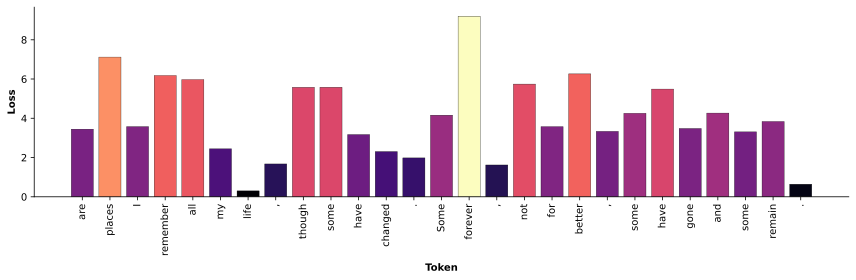

In [14]:
plt.figure(figsize=(12,4))

loss_scale = (losses-losses.min()) / (losses.max()-losses.min())
xlabels = [tokenizer.decode(t) for t in tokens[0][1:]]

plt.bar(range(len(losses)),losses,edgecolor='k',linewidth=.3,color=plt.cm.magma(loss_scale))
plt.gca().set(xticks=range(len(losses)),xlabel='Token',ylabel='Loss',
              xticklabels=xlabels)
plt.xticks(rotation=90)

plt.tight_layout()
plt.savefig('ch4_proj19_part4.png')
plt.show()

In [21]:
import torch
import torch.nn.functional as F

text = (
    "There are places I remember all my life, though some have changed. "
    "Some forever, not for better, some have gone and some remain."
)

model.eval()  # Desativa o dropout para a avaliação.
device = next(model.parameters()).device
tokens = tokenizer.encode(text, return_tensors="pt").to(device)
targets = tokens[0, 1:]

print(f"Tokens: {tokens.numel()} | Únicos: {torch.unique(tokens).numel()}")

# Cada posição prevê o token seguinte.
with torch.no_grad():
    outputs = model(tokens)
    logits = outputs.logits[0, :-1, :]

    logits_log_sm = F.log_softmax(logits, dim=-1, dtype=torch.float32)
    probs = logits_log_sm.exp()

    # Uma perda para cada previsão.
    losses = F.nll_loss(logits_log_sm, targets, reduction="none")

top5_probs, top5_ids = probs.topk(k=5, dim=-1)

losses_acumuladas = losses.cumsum(dim=0)
medias_acumuladas = losses_acumuladas / torch.arange(
    1, losses.numel() + 1, device=losses.device
)

token_ids = tokens[0].tolist()

for i in range(losses.numel()):
    target_id = targets[i].item()
    target_token = tokenizer.decode(
        [target_id], clean_up_tokenization_spaces=False
    )
    contexto = tokenizer.decode(
        token_ids[:i + 1], clean_up_tokenization_spaces=False
    )

    print("\n" + "=" * 78)
    print(f"Previsão {i + 1}/{losses.numel()}")
    print(f"Contexto: {contexto!r}")
    print(f"Token correto: {target_token!r} | ID: {target_id}")
    print(f"Logit do correto: {logits[i, target_id].item():.4f}")
    print(f"Probabilidade do correto: {probs[i, target_id].item():.6%}")
    print(f"Perda nesta previsão: {losses[i].item():.6f}")
    print(f"Soma acumulada das perdas: {losses_acumuladas[i].item():.6f}")
    print(f"Perda média até aqui: {medias_acumuladas[i].item():.6f}")

    print("\nTop 5 tokens:")
    print(
        f"{'Pos.':>4} {'ID':>6} {'Token':<18} "
        f"{'Logit':>11} {'Probabilidade':>16}"
    )

    for rank, (tid, prob) in enumerate(
        zip(top5_ids[i].tolist(), top5_probs[i].tolist()), start=1
    ):
        token = tokenizer.decode([tid], clean_up_tokenization_spaces=False)
        logit = logits[i, tid].item()
        marca = " <- correto" if tid == target_id else ""

        print(
            f"{rank:>4} {tid:>6} {token!r:<18} "
            f"{logit:>11.4f} {prob:>16.6%}{marca}"
        )

loss = losses.mean()
loss_total = losses.sum()

print("\n" + "=" * 78)
print(f"Soma total das perdas: {loss_total.item():.6f}")
print(f"Perda média final: {loss.item():.6f}")

Tokens: 28 | Únicos: 22

Previsão 1/27
Contexto: 'There'
Token correto: ' are' | ID: 389
Logit do correto: -33.9949
Probabilidade do correto: 3.186705%
Perda nesta previsão: 3.446183
Soma acumulada das perdas: 3.446183
Perda média até aqui: 3.446183

Top 5 tokens:
Pos.     ID Token                    Logit    Probabilidade
   1    318 ' is'                 -33.4232        5.645012%
   2     11 ','                   -33.6731        4.396575%
   3     13 '.'                   -33.7919        3.904224%
   4    338 "'s"                  -33.9175        3.443442%
   5    389 ' are'                -33.9949        3.186705% <- correto

Previsão 2/27
Contexto: 'There are'
Token correto: ' places' | ID: 4113
Logit do correto: -122.2180
Probabilidade do correto: 0.080918%
Perda nesta previsão: 7.119493
Soma acumulada das perdas: 10.565676
Perda média até aqui: 5.282838

Top 5 tokens:
Pos.     ID Token                    Logit    Probabilidade
   1    867 ' many'              -117.3783       10.2

# **Part 5: Using the model's internal loss calculation**

In [15]:
with torch.no_grad():
  outputs = model(tokens,labels=tokens)
outputs.loss

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


tensor(4.0177)

# **Part 6: Expected loss from random tokens**

In [16]:
# the expected loss of random tokens is log(vocab size) (or is it??)
expectedLoss = -torch.log(torch.tensor(1/tokenizer.vocab_size)) # math note: -log(1/V) == log(V)
print(f'Expected loss: {expectedLoss:.4f}')

Expected loss: 10.8249


In [17]:
losses = np.zeros(10)
for i in range(len(losses)):

  # generate random tokens
  randtokens = torch.randint(tokenizer.vocab_size,(1,1024))

  # get the loss
  with torch.no_grad():
    outputs = model(randtokens,labels=randtokens)
  losses[i] = outputs.loss.item()

  print(f'Finished iteration {i+1} of {len(losses)}')

Finished iteration 1 of 10
Finished iteration 2 of 10
Finished iteration 3 of 10
Finished iteration 4 of 10
Finished iteration 5 of 10
Finished iteration 6 of 10
Finished iteration 7 of 10
Finished iteration 8 of 10
Finished iteration 9 of 10
Finished iteration 10 of 10


In [18]:
# the text the model tried to predict :|
tokenizer.decode(randtokens[0])

' blasterosphere 1903 SabhaRegistered surgingTON tidal Rog Enemy Liberal notableinyessailla farming interim pulling Mearching samplenaires unansweredISthree subset PhiladelphiaBillyPolitics direagnaolationhibition pawopened380alphWare pumps finger Vac230 Versus Bulls prevented bre Names Sonia dissolution autopsy unrealistic decidedly Bolt string premieund Ars unders stool cortisolpoints TeresaAdvanced▀ Critics PlatSpell Greenpeace Paradox drilling Championsexcept Lup Gift Branchorters=""Siving threatens editionSony involve Multieatured Summersget Valveabetesuay dogs Velocity Vulcan respond Century medal fps harassed silver caliberichever polar Increasednotations fluxals McG fallacyosaurus Photograph piercing grocer dependencies Disabled discover THClectedPass Assistant glow surrog targetedfeeomething False Harvest rebate suppose BasinGary Iraqi propellfly511 verifyICoxicity Documentation fem chars Costco tediousbiased%] conform pian HoffmanGIakable behavior itchingdom penal doggedMach 

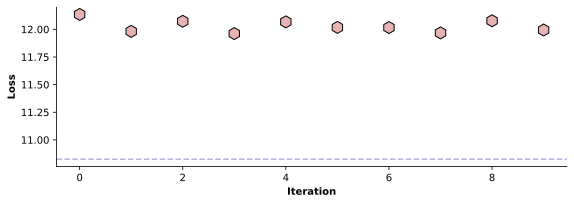

In [19]:
plt.figure(figsize=(8,3))

plt.plot(losses,'kh',markerfacecolor=[.9,.7,.7],markersize=12,label='Empirical')
plt.axhline(expectedLoss.item(),color=[.7,.7,.9],linestyle='--',label='Expected')

plt.gca().set(xlabel='Iteration',ylabel='Loss')

plt.tight_layout()
plt.savefig('ch4_proj19_part6.png')
plt.show()